<a href="https://colab.research.google.com/github/bariscelikk1/cALorie/blob/main/tcn-rebuild/ml/notebooks/03_colab_train_tcn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Train and evaluate a small TCN

Upload one or both landmark ZIPs produced by notebooks 01 and 02. This notebook:

1. audits the manifests and landmark shapes,
2. makes fixed temporal windows,
3. splits by `group_id` before augmentation,
4. trains a small Temporal Convolutional Network,
5. reports accuracy, balanced accuracy, Macro F1, per-class metrics, and a confusion matrix,
6. downloads the best model and its complete report.

The Workout/Fitness dataset has no reliable person IDs. Its clip groups stop windows from the same video leaking across splits, but its score is still a development result. MM-Fit workout IDs provide the stronger person-separated evidence.


In [15]:
%pip install -q --upgrade scikit-learn seaborn

In [16]:
from pathlib import Path
import json
import os
import random
import shutil
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from google.colab import files
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler

SEED = 42
WINDOW = 64
STRIDE = 32
BATCH_SIZE = 64
MAX_EPOCHS = 40
PATIENCE = 8

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [17]:
from google.colab import files
import urllib.request

# The three versioned landmark archives are stored on the project branch.
# Keep this True for a reproducible run without using Colab's upload dialog.
DOWNLOAD_FROM_GITHUB = True
ARTIFACT_BASE = (
    "https://raw.githubusercontent.com/bariscelikk1/cALorie/"
    "feat/tcn-rebuild/ml/artifacts/v1/landmarks"
)
LANDMARK_ARCHIVES = [
    "calorie_workoutfitness_landmarks_v1.zip",
    "calorie_mmfit_landmarks_v1.zip",
    "calorie_mmfit_unknown_v1.zip",
]

if DOWNLOAD_FROM_GITHUB:
    zip_names = []
    for name in LANDMARK_ARCHIVES:
        destination = Path("/content") / name
        print("Downloading", name)
        request = urllib.request.Request(
            f"{ARTIFACT_BASE}/{name}",
            headers={"User-Agent": "Mozilla/5.0"},
        )
        with urllib.request.urlopen(request) as response, destination.open("wb") as output:
            shutil.copyfileobj(response, output)
        zip_names.append(str(destination))
        print(f"  saved {destination} ({destination.stat().st_size / 1e6:.1f} MB)")
else:
    print("Upload all three landmark ZIPs")
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
    assert zip_names, "Upload at least one landmark ZIP from notebook 01 or 02."

SOURCE_ROOT = Path("/content/landmark_sources")
if SOURCE_ROOT.exists():
    shutil.rmtree(SOURCE_ROOT)
SOURCE_ROOT.mkdir()

for index, name in enumerate(zip_names):
    destination = SOURCE_ROOT / f"source_{index}"
    destination.mkdir()
    with zipfile.ZipFile(name) as archive:
        archive.extractall(destination)
    print(Path(name).name, "->", destination)


  saved /content/calorie_workoutfitness_landmarks_v1.zip (9.8 MB)
  saved /content/calorie_mmfit_landmarks_v1.zip (51.1 MB)
  saved /content/calorie_mmfit_unknown_v1.zip (4.2 MB)
calorie_workoutfitness_landmarks_v1.zip -> /content/landmark_sources/source_0
calorie_mmfit_landmarks_v1.zip -> /content/landmark_sources/source_1
calorie_mmfit_unknown_v1.zip -> /content/landmark_sources/source_2


In [18]:
# Load every manifest and resolve each NPZ relative to that manifest.
frames = []
for manifest_path in SOURCE_ROOT.rglob("manifest.csv"):
    frame = pd.read_csv(manifest_path).fillna("")
    frame["npz_path"] = frame["output_path"].map(lambda value: str(manifest_path.parent / value))
    frames.append(frame)

assert frames, "No manifest.csv was found inside the uploaded ZIP(s)."
manifest = pd.concat(frames, ignore_index=True)
manifest = manifest[(manifest["status"] == "ok") & manifest["npz_path"].map(lambda p: Path(p).exists())].copy()

if "group_id" not in manifest or manifest["group_id"].eq("").any():
    manifest["group_id"] = manifest.apply(
        lambda row: f"{row['source_dataset']}:{row['clip_id']}", axis=1
    )

print("Valid clips:", len(manifest))
print("Datasets:")
print(manifest["source_dataset"].value_counts())
print()
print("Classes:")
print(manifest["canonical_class"].value_counts().sort_index())
print()
print("Unique groups:", manifest["group_id"].nunique())

Valid clips: 1236
Datasets:
source_dataset
mm-fit                  868
workoutfitness-video    368
Name: count, dtype: int64

Classes:
canonical_class
bench_press          57
bicep_curl          118
deadlift             32
dumbbell_row         64
jumping_jack         57
lat_pulldown         48
lateral_raise        93
lunge                62
plank                 7
pull_up              26
push_up             121
shoulder_press       77
sit_up               65
squat                93
tricep_extension     64
unknown             252
Name: count, dtype: int64

Unique groups: 389


## Diagnostic 1 — class/source coverage

Before training, check whether every exercise is represented by multiple datasets. A class that exists in only one source can become entangled with that dataset's camera or pose-estimator style. This table does not measure accuracy; it exposes that risk.


In [19]:
coverage = pd.crosstab(manifest["canonical_class"], manifest["source_dataset"])
display(coverage)

source_count = (coverage > 0).sum(axis=1)
single_source_classes = source_count[source_count == 1].index.tolist()
print("Classes represented by only one dataset:", single_source_classes)
if single_source_classes:
    print(
        "WARNING: These classes may learn dataset/landmark style instead of the movement. "
        "External evidence is especially important for them."
    )


source_dataset,mm-fit,workoutfitness-video
canonical_class,,
bench_press,0,57
bicep_curl,59,59
deadlift,0,32
dumbbell_row,64,0
jumping_jack,57,0
lat_pulldown,0,48
lateral_raise,56,37
lunge,62,0
plank,0,7


Classes represented by only one dataset: ['bench_press', 'deadlift', 'dumbbell_row', 'jumping_jack', 'lat_pulldown', 'lunge', 'plank', 'pull_up', 'sit_up', 'tricep_extension', 'unknown']


## Windows

The TCN needs equal-length batches. A 64-frame window represents about 4.3 seconds at 15 FPS. Long clips create overlapping windows; short clips are padded by repeating their final frame. Every window keeps its original clip/person group, so related windows stay in one split.


In [20]:
def resample_sequence(sequence, source_fps, target_fps=15):
    if not source_fps or abs(float(source_fps) - target_fps) < 0.1:
        return sequence
    duration = (len(sequence) - 1) / float(source_fps)
    target_length = max(2, int(round(duration * target_fps)) + 1)
    old_x = np.linspace(0, duration, len(sequence))
    new_x = np.linspace(0, duration, target_length)
    flat = sequence.reshape(len(sequence), -1)
    sampled = np.stack([np.interp(new_x, old_x, flat[:, i]) for i in range(flat.shape[1])], axis=1)
    return sampled.reshape(target_length, 17, 4).astype(np.float32)


windows, labels, groups, clip_ids, sources = [], [], [], [], []
for row in manifest.itertuples(index=False):
    with np.load(row.npz_path, allow_pickle=False) as item:
        sequence = item["landmarks"].astype(np.float32)
    if sequence.ndim != 3 or sequence.shape[1:] != (17, 4):
        print("Skipping unexpected shape:", row.npz_path, sequence.shape)
        continue
    sequence = resample_sequence(sequence, getattr(row, "source_fps", 15) or 15)
    starts = list(range(0, max(1, len(sequence) - WINDOW + 1), STRIDE))
    if len(sequence) > WINDOW and starts[-1] != len(sequence) - WINDOW:
        starts.append(len(sequence) - WINDOW)
    for start in starts:
        window = sequence[start:start + WINDOW]
        if len(window) < WINDOW:
            window = np.concatenate([window, np.repeat(window[-1:], WINDOW - len(window), axis=0)])
        windows.append(window)
        labels.append(row.canonical_class)
        groups.append(row.group_id)
        clip_ids.append(row.clip_id)
        sources.append(row.source_dataset)

X = np.asarray(windows, dtype=np.float32)
labels = np.asarray(labels)
groups = np.asarray(groups)
clip_ids = np.asarray(clip_ids)
sources = np.asarray(sources)
CLASSES = sorted(np.unique(labels).tolist())
class_to_id = {name: index for index, name in enumerate(CLASSES)}
y = np.asarray([class_to_id[name] for name in labels], dtype=np.int64)

print("Windows:", X.shape)
print("Classes:", CLASSES)
print(pd.Series(labels).value_counts().sort_index())

Windows: (6386, 64, 17, 4)
Classes: ['bench_press', 'bicep_curl', 'deadlift', 'dumbbell_row', 'jumping_jack', 'lat_pulldown', 'lateral_raise', 'lunge', 'plank', 'pull_up', 'push_up', 'shoulder_press', 'sit_up', 'squat', 'tricep_extension', 'unknown']
bench_press          69
bicep_curl          577
deadlift             47
dumbbell_row        492
jumping_jack        243
lat_pulldown         55
lateral_raise       646
lunge               791
plank                78
pull_up              43
push_up             540
shoulder_press      635
sit_up              713
squat               642
tricep_extension    563
unknown             252
Name: count, dtype: int64


In [21]:
# Fold 0 is test. Fold 0 of the remaining data is validation.
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_val_idx, test_idx = next(outer.split(X, y, groups))

inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
inner_train, inner_val = next(inner.split(X[train_val_idx], y[train_val_idx], groups[train_val_idx]))
train_idx = train_val_idx[inner_train]
val_idx = train_val_idx[inner_val]

for name, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    print(name, "windows=", len(idx), "groups=", len(np.unique(groups[idx])), "classes=", len(np.unique(y[idx])))

assert not (set(groups[train_idx]) & set(groups[val_idx]))
assert not (set(groups[train_idx]) & set(groups[test_idx]))
assert not (set(groups[val_idx]) & set(groups[test_idx]))

train windows= 3868 groups= 224 classes= 16
validation windows= 1241 groups= 76 classes= 16
test windows= 1277 groups= 89 classes= 16


In [22]:
class PoseWindowDataset(Dataset):
    def __init__(self, indices, training=False):
        self.indices = np.asarray(indices)
        self.training = training

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        actual = self.indices[index]
        sample = X[actual].copy()
        if self.training:
            # Light pose noise improves robustness without changing the action label.
            sample[:, :, :3] += np.random.normal(0, 0.01, sample[:, :, :3].shape).astype(np.float32)
        # Use shared x/y only. MM-Fit has no MediaPipe z/visibility values, so
        # including them would let the network identify the dataset source.
        sample = sample[:, :, :2].reshape(WINDOW, -1).T
        return torch.from_numpy(sample), torch.tensor(y[actual], dtype=torch.long)


train_counts = np.bincount(y[train_idx], minlength=len(CLASSES))
sample_weights = 1.0 / np.maximum(train_counts[y[train_idx]], 1)
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

train_loader = DataLoader(PoseWindowDataset(train_idx, True), batch_size=BATCH_SIZE, sampler=sampler)
val_loader = DataLoader(PoseWindowDataset(val_idx), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(PoseWindowDataset(test_idx), batch_size=BATCH_SIZE, shuffle=False)

In [23]:
class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation, dropout=0.2):
        super().__init__()
        padding = dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, 3, padding=padding, dilation=dilation),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(out_channels, out_channels, 3, padding=padding, dilation=dilation),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        return torch.relu(self.net(x) + self.residual(x))


class SmallTCN(nn.Module):
    def __init__(self, input_features, num_classes):
        super().__init__()
        channels = [64, 96, 128, 128]
        blocks = []
        current = input_features
        for level, output in enumerate(channels):
            blocks.append(TemporalBlock(current, output, dilation=2 ** level))
            current = output
        self.features = nn.Sequential(*blocks)
        self.classifier = nn.Linear(current, num_classes)

    def forward(self, x):
        temporal_features = self.features(x)
        return self.classifier(temporal_features.mean(dim=-1))

## Diagnostic 2 — tiny-overfit sanity check

This deliberately asks a fresh TCN to memorize a few training windows. It is not a real accuracy score. Reaching about 98–100% means the tensor shapes, labels, loss, optimizer, and model capacity can fit the task. Failure points to a pipeline or optimization problem that should be fixed before collecting more data.


In [24]:
tiny_classes = np.unique(y[train_idx])[: min(4, len(np.unique(y[train_idx])))]
tiny_indices = np.concatenate([
    train_idx[y[train_idx] == class_id][:8]
    for class_id in tiny_classes
])

tiny_features = X[tiny_indices, :, :, :2].reshape(len(tiny_indices), WINDOW, -1).transpose(0, 2, 1)
tiny_targets = y[tiny_indices]
tiny_x = torch.from_numpy(tiny_features).to(DEVICE)
tiny_y = torch.from_numpy(tiny_targets).long().to(DEVICE)

torch.manual_seed(SEED)
tiny_model = SmallTCN(17 * 2, len(CLASSES)).to(DEVICE)
tiny_optimizer = torch.optim.AdamW(tiny_model.parameters(), lr=3e-3, weight_decay=0.0)
tiny_criterion = nn.CrossEntropyLoss()

for step in range(1, 301):
    tiny_model.train()
    tiny_optimizer.zero_grad(set_to_none=True)
    tiny_logits = tiny_model(tiny_x)
    tiny_loss = tiny_criterion(tiny_logits, tiny_y)
    tiny_loss.backward()
    tiny_optimizer.step()
    if step % 50 == 0 or step == 1:
        tiny_accuracy = (tiny_logits.argmax(1) == tiny_y).float().mean().item()
        print(f"step={step:03d} loss={tiny_loss.item():.4f} accuracy={tiny_accuracy:.3f}")

tiny_model.eval()
with torch.no_grad():
    tiny_accuracy = (tiny_model(tiny_x).argmax(1) == tiny_y).float().mean().item()

print(f"Tiny-overfit final accuracy: {tiny_accuracy:.3f} on {len(tiny_indices)} windows")
if tiny_accuracy >= 0.98:
    print("PASS: the training pipeline can memorize this small sample.")
else:
    print("FAIL: inspect labels, tensors, normalization, loss, and optimization before adding data.")

del tiny_model, tiny_optimizer, tiny_x, tiny_y
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Restore the seed so this diagnostic does not change the real experiment.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


step=001 loss=3.1506 accuracy=0.000
step=050 loss=0.0003 accuracy=1.000
step=100 loss=0.0001 accuracy=1.000
step=150 loss=0.0001 accuracy=1.000
step=200 loss=0.0000 accuracy=1.000
step=250 loss=0.0000 accuracy=1.000
step=300 loss=0.0000 accuracy=1.000
Tiny-overfit final accuracy: 1.000 on 32 windows
PASS: the training pipeline can memorize this small sample.


In [25]:
model = SmallTCN(17 * 2, len(CLASSES)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=3, factor=0.5)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


SmallTCN(
  (features): Sequential(
    (0): TemporalBlock(
      (net): Sequential(
        (0): Conv1d(34, 64, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Dropout(p=0.2, inplace=False)
        (4): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
        (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (6): ReLU()
        (7): Dropout(p=0.2, inplace=False)
      )
      (residual): Conv1d(34, 64, kernel_size=(1,), stride=(1,))
    )
    (1): TemporalBlock(
      (net): Sequential(
        (0): Conv1d(64, 96, kernel_size=(3,), stride=(1,), padding=(2,), dilation=(2,))
        (1): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Dropout(p=0.2, inplace=False)
        (4): Conv1d(96, 96, kernel_size=(3,), stride=(1,), padding=(2,), dilation=(2,)

In [26]:
def run_epoch(loader, training=False):
    model.train(training)
    losses, truths, predictions = [], [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for features, targets in loader:
            features, targets = features.to(DEVICE), targets.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
            losses.append(loss.item() * len(targets))
            truths.extend(targets.cpu().numpy())
            predictions.extend(logits.argmax(1).cpu().numpy())
    return sum(losses) / len(truths), f1_score(truths, predictions, average="macro", zero_division=0)


history = []
best_f1 = -1.0
epochs_without_improvement = 0
BEST_PATH = Path("/content/best_tcn.pt")

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_f1 = run_epoch(train_loader, training=True)
    val_loss, val_f1 = run_epoch(val_loader, training=False)
    scheduler.step(val_f1)
    history.append({"epoch": epoch, "train_loss": train_loss, "train_macro_f1": train_f1, "val_loss": val_loss, "val_macro_f1": val_f1})
    print(f"{epoch:02d} train loss={train_loss:.4f} F1={train_f1:.3f} | val loss={val_loss:.4f} F1={val_f1:.3f}")
    if val_f1 > best_f1 + 1e-4:
        best_f1 = val_f1
        epochs_without_improvement = 0
        torch.save(model.state_dict(), BEST_PATH)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping")
            break

model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))

01 train loss=0.7241 F1=0.791 | val loss=1.1817 F1=0.669
02 train loss=0.2120 F1=0.934 | val loss=0.9725 F1=0.765
03 train loss=0.1839 F1=0.940 | val loss=1.1519 F1=0.724
04 train loss=0.1610 F1=0.946 | val loss=1.0387 F1=0.712
05 train loss=0.1173 F1=0.966 | val loss=0.7883 F1=0.796
06 train loss=0.1196 F1=0.962 | val loss=1.2893 F1=0.724
07 train loss=0.0823 F1=0.973 | val loss=0.9823 F1=0.784
08 train loss=0.0889 F1=0.973 | val loss=0.9466 F1=0.777
09 train loss=0.0655 F1=0.983 | val loss=1.0262 F1=0.789
10 train loss=0.0423 F1=0.990 | val loss=0.9601 F1=0.796
11 train loss=0.0318 F1=0.991 | val loss=0.8415 F1=0.803
12 train loss=0.0268 F1=0.993 | val loss=0.7173 F1=0.818
13 train loss=0.0251 F1=0.994 | val loss=0.7974 F1=0.805
14 train loss=0.0311 F1=0.992 | val loss=0.8645 F1=0.824
15 train loss=0.0282 F1=0.990 | val loss=0.9195 F1=0.801
16 train loss=0.0240 F1=0.994 | val loss=0.8550 F1=0.839
17 train loss=0.0176 F1=0.996 | val loss=1.0555 F1=0.807
18 train loss=0.0253 F1=0.994 |

<All keys matched successfully>

In [27]:
def predict(loader):
    model.eval()
    truths, predictions, probabilities = [], [], []
    with torch.no_grad():
        for features, targets in loader:
            logits = model(features.to(DEVICE))
            probs = logits.softmax(1).cpu().numpy()
            truths.extend(targets.numpy())
            predictions.extend(probs.argmax(1))
            probabilities.extend(probs)
    return np.asarray(truths), np.asarray(predictions), np.asarray(probabilities)


y_true, y_pred, y_prob = predict(test_loader)
metrics = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    "seed": SEED,
    "window_frames": WINDOW,
    "stride_frames": STRIDE,
    "classes": CLASSES,
}
print(json.dumps(metrics, indent=2))
report = classification_report(
    y_true, y_pred, labels=np.arange(len(CLASSES)),
    target_names=CLASSES, output_dict=True, zero_division=0,
)
display(pd.DataFrame(report).T.round(3))

{
  "accuracy": 0.8645262333594361,
  "balanced_accuracy": 0.865716308896661,
  "macro_f1": 0.814156660954557,
  "seed": 42,
  "window_frames": 64,
  "stride_frames": 32,
  "classes": [
    "bench_press",
    "bicep_curl",
    "deadlift",
    "dumbbell_row",
    "jumping_jack",
    "lat_pulldown",
    "lateral_raise",
    "lunge",
    "plank",
    "pull_up",
    "push_up",
    "shoulder_press",
    "sit_up",
    "squat",
    "tricep_extension",
    "unknown"
  ]
}


,precision,recall,f1-score,support
bench_press,0.524,0.786,0.629,14.000
bicep_curl,0.940,0.956,0.948,114.000
deadlift,0.818,1.000,0.900,9.000
dumbbell_row,0.887,0.598,0.714,92.000
jumping_jack,0.977,1.000,0.989,43.000
lat_pulldown,0.417,0.909,0.571,11.000
lateral_raise,0.983,0.944,0.964,126.000
lunge,1.000,0.946,0.972,147.000
plank,0.981,1.000,0.991,53.000
pull_up,0.333,0.750,0.462,8.000


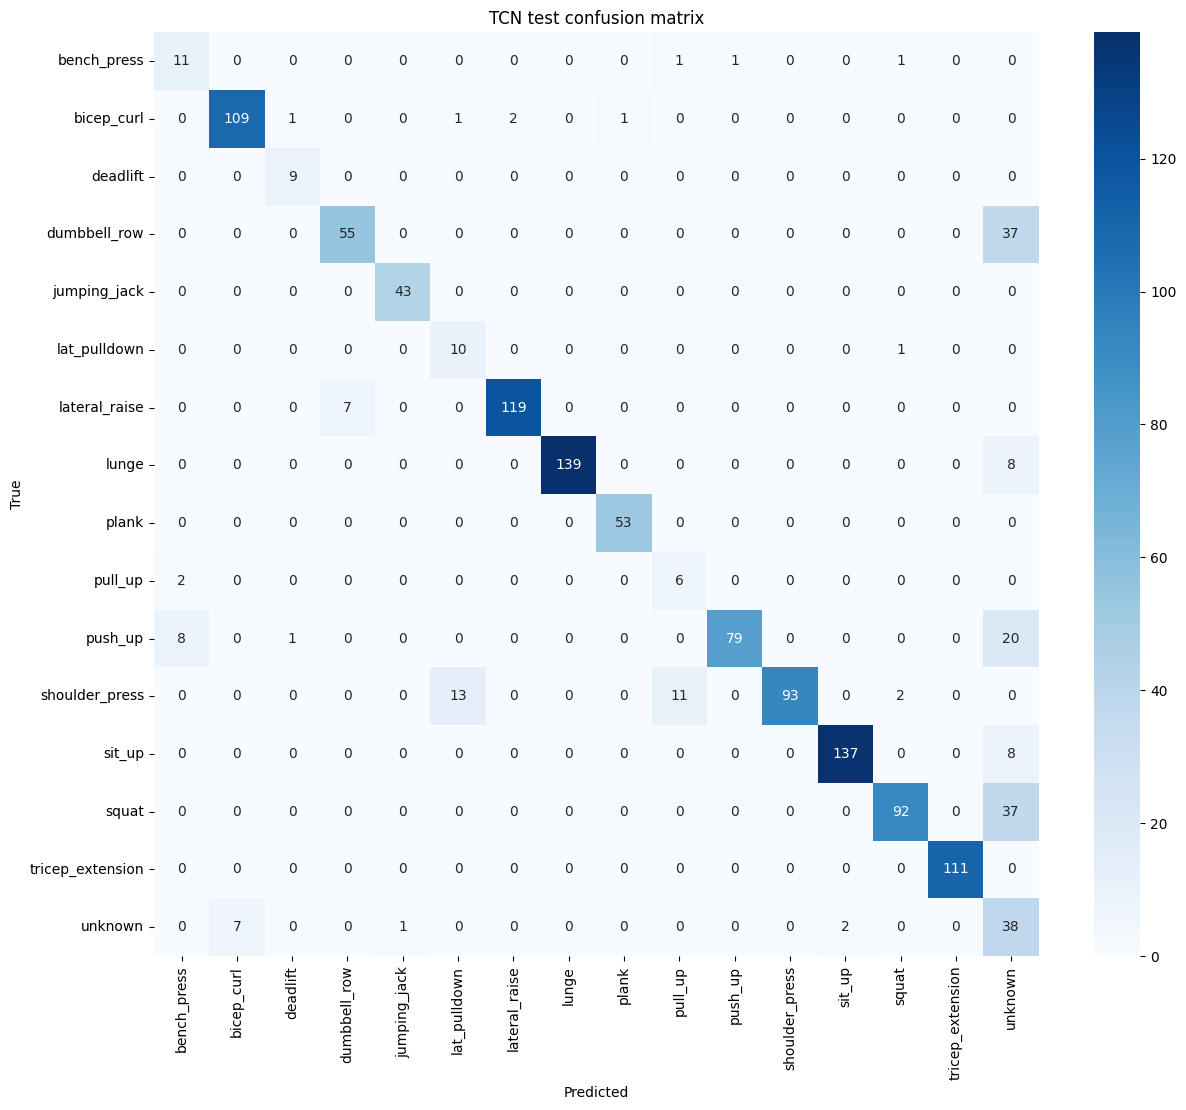

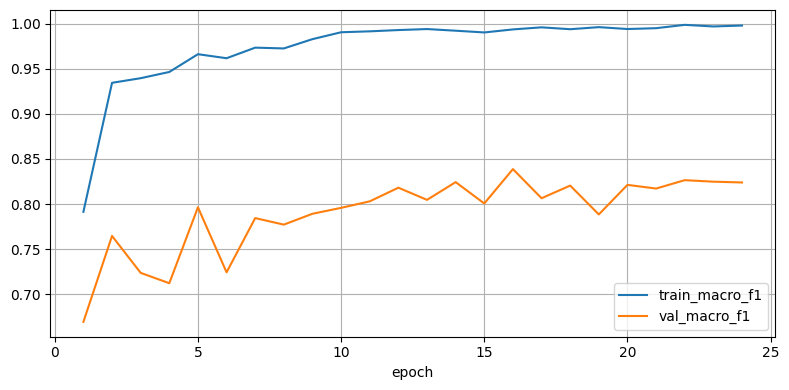

Report ZIP: /content/calorie_tcn_report.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
REPORT_ROOT = Path("/content/calorie_tcn_report")
REPORT_ROOT.mkdir(exist_ok=True)

matrix = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASSES)))
plt.figure(figsize=(max(8, len(CLASSES) * 0.8), max(6, len(CLASSES) * 0.7)))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("TCN test confusion matrix")
plt.tight_layout()
plt.savefig(REPORT_ROOT / "confusion_matrix.png", dpi=180)
plt.show()

history_frame = pd.DataFrame(history)
history_frame.to_csv(REPORT_ROOT / "training_history.csv", index=False)
history_frame.plot(x="epoch", y=["train_macro_f1", "val_macro_f1"], figsize=(8, 4), grid=True)
plt.tight_layout()
plt.savefig(REPORT_ROOT / "learning_curve.png", dpi=180)
plt.show()

torch.save({
    "state_dict": model.state_dict(),
    "classes": CLASSES,
    "window_frames": WINDOW,
    "input_features": 34,
}, REPORT_ROOT / "tcn_model.pt")
(REPORT_ROOT / "metrics.json").write_text(json.dumps(metrics, indent=2))
(REPORT_ROOT / "classification_report.json").write_text(json.dumps(report, indent=2))

prediction_rows = manifest.iloc[0:0].copy()  # schema reminder; window predictions live below
pd.DataFrame({
    "clip_id": clip_ids[test_idx],
    "source_dataset": sources[test_idx],
    "true_class": [CLASSES[i] for i in y_true],
    "predicted_class": [CLASSES[i] for i in y_pred],
    "confidence": y_prob.max(axis=1),
}).to_csv(REPORT_ROOT / "test_window_predictions.csv", index=False)

zip_path = shutil.make_archive("/content/calorie_tcn_report", "zip", root_dir=REPORT_ROOT)
print("Report ZIP:", zip_path)
files.download(zip_path)